In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Website Conversion Funnel Analysis: 
## Identifying Conversion Bottlenecks and Device-Specific Purchase Friction

## Business Problem
Marketing efforts are generating traffic, but only a small proportion of users complete the purchase journey. The analysis aims to identify where users abandon the funnel, determine whether performance differs across customer segments, and recommend areas for further investigation.

## Business Objectives
* Measure overall and stage-level funnel conversion.
* Identify the most significant points of customer loss.
* Compare performance across devices and genders.
* Examine conversion patterns across monthly user cohorts.
* Recommend the highest-priority areas for investigation.

## Dataset Overview

This dataset contains five relational tables representing different stages of an e-commerce conversion funnel:

* User Table
* Home Page Table
* Search Page Table
* Payment Page Table
* Payment Confirmation Table

Each table records users who successfully reached that stage of the journey.

## Tools Used
Python, Pandas, NumPy, Matplotlib, Seaborn and Plotly.

## Import the datasets to begin with data cleaning and EDA

In [2]:
ut = pd.read_csv('user_table.csv')
ht = pd.read_csv('home_page_table.csv')
st = pd.read_csv('search_page_table.csv')
pt = pd.read_csv('payment_page_table.csv')
pct = pd.read_csv('payment_confirmation_table.csv')

## Data Cleaning

### 1. Check for null values

In [3]:
missing_summary = pd.DataFrame({
    'Dataset': ['Users', 'Home', 'Search', 'Payment', 'Confirmation'],
    'Null Values': [
        ut.isna().sum().sum(),
        ht.isna().sum().sum(),
        st.isna().sum().sum(),
        pt.isna().sum().sum(),
        pct.isna().sum().sum()
    ]
})

missing_summary

,Dataset,Null Values
0,Users,0
1,Home,0
2,Search,0
3,Payment,0
4,Confirmation,0


### 2. Check for Incorrect Datatypes

In [4]:
ut.dtypes

user_id     int64
date       object
device     object
sex        object
dtype: object

In [5]:
ut['date'] = pd.to_datetime(ut['date'])

In [6]:
ht.dtypes

user_id     int64
page       object
dtype: object

In [7]:
st.dtypes

user_id     int64
page       object
dtype: object

In [8]:
pt.dtypes

user_id     int64
page       object
dtype: object

In [9]:
pct.dtypes

user_id     int64
page       object
dtype: object

No null values were found in any of the tables.

Datatypes in all the tables were correct except the date column in the users table.

### 3. Check for duplicates and remove them

In [10]:
print('No. of Duplicates')
print('Users:', ut.duplicated().sum())
print('Home:', ht.duplicated().sum())
print('Search:', st.duplicated().sum())
print('Payment:', pt.duplicated().sum())
print('Payment Confirmation:', pct.duplicated().sum())

No. of Duplicates
Users: 0
Home: 0
Search: 0
Payment: 0
Payment Confirmation: 0


No duplicate rows were found in the dataset.

### 4. Verify funnel integrity

In [11]:
invalid_search = st[~st['user_id'].isin(ht['user_id'])]
invalid_payment = pt[~pt['user_id'].isin(st['user_id'])]
invalid_confirmation = pct[~pct['user_id'].isin(pt['user_id'])]


print('Invalid Search users:', len(invalid_search))
print('Invalid Payment users:', len(invalid_payment))
print('Invalid Confirmation users:', len(invalid_confirmation))

Invalid Search users: 0
Invalid Payment users: 0
Invalid Confirmation users: 0


Validated funnel integrity by confirming that every user in a later funnel stage also exists in its preceding stage, with no inconsistencies detected.

Overall, the dataset was already clean. We just had to change the datatype of the date column.

## Exploratory Data Analysis (EDA)

## Overview

### 1. How is the funnel performing overall?

In [12]:
# Calculate Overview metrics

total_users = ut['user_id'].nunique()

home_users = ht['user_id'].nunique()
search_users = st['user_id'].nunique()
payment_users = pt['user_id'].nunique()
confirmation_users = pct['user_id'].nunique()

overall_conversion = (confirmation_users / home_users) * 100

In [13]:
from IPython.display import display, HTML

kpi_cards = f"""
<div style="
    display: flex;
    gap: 20px;
    margin: 15px 0 25px 0;
    flex-wrap: wrap;
">

    <div style="
        flex: 1;
        min-width: 180px;
        padding: 22px;
        border: 1px solid #d9d9d9;
        border-radius: 10px;
        text-align: center;
        background-color: #f8f9fa;
    ">
        <div style="
            font-size: 15px;
            color: #555;
            margin-bottom: 8px;
        ">
            Total Users
        </div>

        <div style="
            font-size: 30px;
            font-weight: bold;
            color: #222;
        ">
            {total_users:,}
        </div>
    </div>

    <div style="
        flex: 1;
        min-width: 180px;
        padding: 22px;
        border: 1px solid #d9d9d9;
        border-radius: 10px;
        text-align: center;
        background-color: #f8f9fa;
    ">
        <div style="
            font-size: 15px;
            color: #555;
            margin-bottom: 8px;
        ">
            Confirmed Users
        </div>

        <div style="
            font-size: 30px;
            font-weight: bold;
            color: #222;
        ">
            {confirmation_users:,}
        </div>
    </div>

    <div style="
        flex: 1;
        min-width: 180px;
        padding: 22px;
        border: 1px solid #d9d9d9;
        border-radius: 10px;
        text-align: center;
        background-color: #f8f9fa;
    ">
        <div style="
            font-size: 15px;
            color: #555;
            margin-bottom: 8px;
        ">
            Overall Conversion Rate
        </div>

        <div style="
            font-size: 30px;
            font-weight: bold;
            color: #222;
        ">
            {overall_conversion:.2f}%
        </div>
    </div>

</div>
"""

display(HTML(kpi_cards))

In [14]:
# Stage wise user count
home_users = ht['user_id'].nunique()
search_users = st['user_id'].nunique()
payment_users = pt['user_id'].nunique()
confirmation_users = pct['user_id'].nunique()

funnel_data = pd.DataFrame(({
    'Stage': [
        'Home',
        'Search',
        'Payment',
        'Confirmed'
    ],
    'Users': [
        home_users,
        search_users,
        payment_users,
        confirmation_users
    ]
}))
funnel_data

,Stage,Users
0,Home,90400
1,Search,45200
2,Payment,6030
3,Confirmed,452


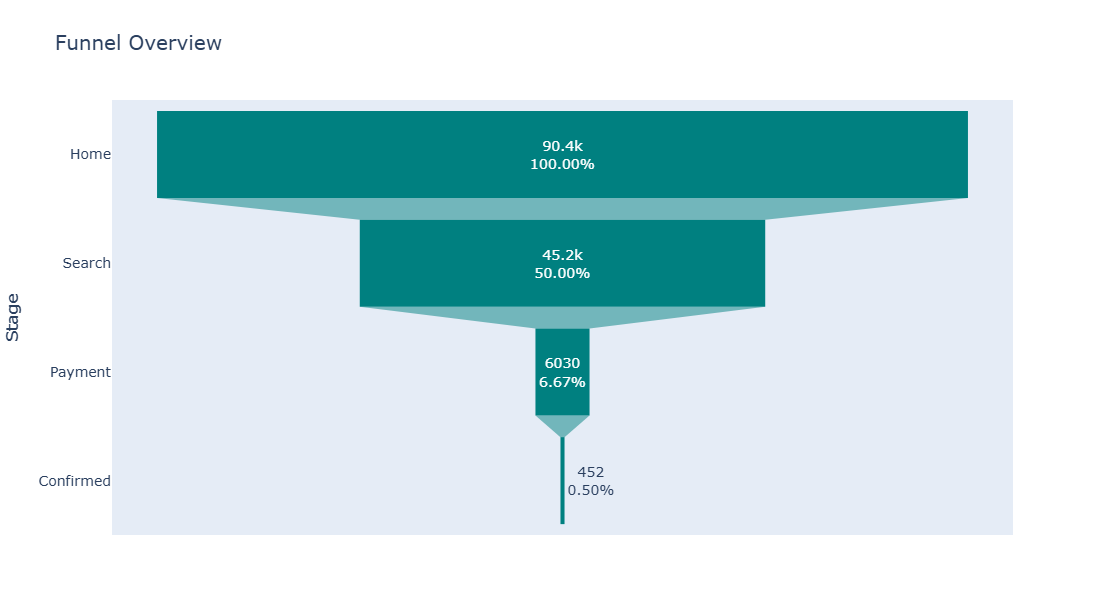

In [15]:
fig = px.funnel(funnel_data, x='Users', y='Stage', title='Funnel Overview')
fig.update_layout(font=dict(size=14))
fig.update_traces(marker=dict(color='teal'))
fig.update_traces(textinfo="value+percent initial", texttemplate="%{value}<br>%{percentInitial:.2%}")
fig.update_layout(width=1100, height=600)
fig.show()

The funnel begins with 90,400 users, but only 452 users complete the purchase journey, resulting in an overall conversion rate of just 0.5%. This indicates a substantial loss of potential customers before purchase completion and highlights significant opportunities to improve funnel performance.

A detailed analysis of user progression through each funnel stage is presented in the following section to identify where the majority of users abandon the journey.

## Funnel Analysis

### 2. Where are customers leaving the funnel?

In [16]:
# Conversion Rates at each funnel stage 
home_to_search = (search_users / home_users) * 100
search_to_payment = (payment_users / search_users) * 100
payment_to_confirmation = (confirmation_users / payment_users) * 100

# Stage-wise drop-offs
drop_home_search = home_users - search_users
drop_search_payment = search_users - payment_users
drop_payment_confirmation = payment_users - confirmation_users

# Drop-off percentages
drop_pct_home_search = (drop_home_search / home_users) * 100
drop_pct_search_payment = (drop_search_payment / search_users) * 100
drop_pct_payment_confirmation = (drop_payment_confirmation / payment_users) * 100

In [17]:
funnel_summary = pd.DataFrame({
    'Stage': [
        'Home → Search',
        'Search → Payment',
        'Payment → Confirmation'
    ],
    'Users at Previous Stage': [
        home_users,
        search_users,
        payment_users
    ],
    'Users at Current Stage': [
        search_users,
        payment_users,
        confirmation_users
    ],
    'Conversion Rate (%)': [
        round(home_to_search, 2),
        round(search_to_payment, 2),
        round(payment_to_confirmation, 2)
    ],
    'Drop-offs': [
        drop_home_search,
        drop_search_payment,
        drop_payment_confirmation
    ],
    'Drop-off Rate (%)': [
        round(drop_pct_home_search, 2),
        round(drop_pct_search_payment, 2),
        round(drop_pct_payment_confirmation, 2)
    ]
})

funnel_summary

,Stage,Users at Previous Stage,Users at Current Stage,Conversion Rate (%),Drop-offs,Drop-off Rate (%)
0,Home → Search,90400,45200,50.00,45200,50.00
1,Search → Payment,45200,6030,13.34,39170,86.66
2,Payment → Confirmation,6030,452,7.50,5578,92.50


The largest absolute loss of users occurs between the Search and Payment stages, where 39,170 users abandon the funnel and only 13.34% progress to payment. However, the highest proportional loss occurs between Payment and Confirmation, where 92.5% of users fail to complete their purchase.

The Search → Payment and Payment → Confirmation stages should be prioritized for investigation, as reducing friction in these stages offers the greatest opportunity to improve overall funnel conversion.

## Device Analysis

### 3. Which device contributes the most users?

In [18]:
home_device = ht.merge(ut[['user_id', 'device']], on='user_id')

device_users = home_device.groupby('device')['user_id'].nunique().sort_values(ascending=False).reset_index(name='users')
device_users

,device,users
0,Desktop,60200
1,Mobile,30200


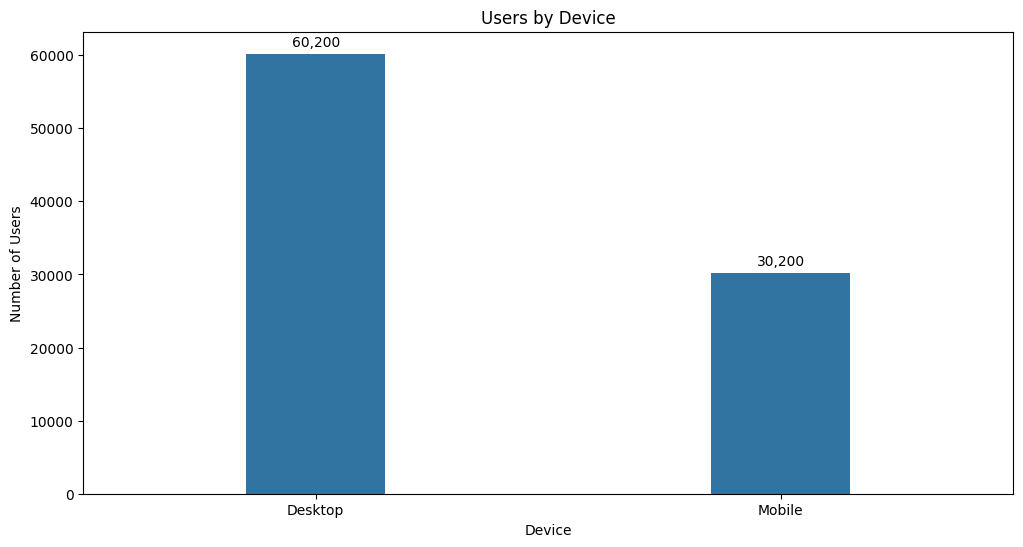

In [19]:
plt.figure(figsize=(12, 6))
dev_bar = sns.barplot(data = device_users, x='device', y='users', legend=False, width=0.3)

for container in dev_bar.containers:
    dev_bar.bar_label(container, fmt='{:,.0f}', padding=3)

plt.title("Users by Device")
plt.ylabel("Number of Users")
plt.xlabel("Device")
plt.show()

Desktop contributes 60,200 users (66.6% of total funnel traffic), while mobile contributes 30,200 users (33.4%). This indicates that the business attracts approximately twice as many users through desktop as through mobile devices.

Desktop accounts for two-thirds of total funnel traffic, making it the primary source of customer acquisition. Whether this traffic translates into purchases is evaluated in the subsequent analysis.

### 4. Which device has the highest conversion rate?

In [20]:
home_device = ht.merge(ut[['user_id', 'device']], on='user_id')

confirmation_device = pct.merge(ut[['user_id', 'device']], on='user_id')

In [21]:
home_counts = home_device.groupby('device')['user_id'].nunique().reset_index(name = "home_users")
confirmation_counts = confirmation_device.groupby('device')['user_id'].nunique().reset_index(name = "confirmed_users")

In [22]:
device_conversions = home_counts.merge(confirmation_counts)

device_conversions['Conversion Rate (%)'] = (device_conversions['confirmed_users']/device_conversions['home_users']*100).round(2)
device_conversions

,device,home_users,confirmed_users,Conversion Rate (%)
0,Desktop,60200,150,0.25
1,Mobile,30200,302,1.00


Although desktop contributes nearly twice as many users as mobile, mobile users convert four times better (1.00% vs. 0.25%). This indicates that the mobile users have significantly higher conversion rates than desktop users.

The reasons behind the poor conversion performance of desktop users should be investigated, as improvements to the desktop purchase journey could generate the largest increase in overall conversions due to its substantially higher traffic volume.

## Gender Analysis

### 5. How is the user base distributed across genders?

In [23]:
gender_distribution = (ut.groupby('sex')['user_id'].nunique().reset_index(name='users'))

gender_distribution['User Share (%)'] = (gender_distribution['users'] / gender_distribution['users'].sum()* 100).round(2)

gender_distribution

,sex,users,User Share (%)
0,Female,45075,49.86
1,Male,45325,50.14


In [24]:
fig = px.bar(gender_distribution, x = 'users', y = 'sex', text = gender_distribution['User Share (%)'].astype(str) + "%", title = 'User Gender Distribution')
fig.update_layout(width=1100, height=600)
fig.update_layout(bargap = 0.6)
fig.show()

The user base is almost evenly distributed across genders, with 50.14% male users and 49.86% female users. This indicates balanced customer acquisition across both genders, and no significant skew is observed in the composition of the user base.

### 6. Which gender has the highest conversion rate?

In [25]:
user_gender = ut[['user_id', 'sex']]

home_gender = ht.merge(user_gender, on='user_id', how='left')
confirmation_gender = pct.merge(user_gender, on='user_id', how='left')

In [26]:
home_counts = home_gender.groupby('sex')['user_id'].nunique().reset_index(name = 'home_users')
confirmation_counts = confirmation_gender.groupby('sex')['user_id'].nunique().reset_index(name = 'confirmation_users')

In [27]:
gender_conversions = home_counts.merge(confirmation_counts)
gender_conversions['Overall Conversion (%)'] = (gender_conversions['confirmation_users'] / gender_conversions['home_users'] * 100).round(2)
gender_conversions

,sex,home_users,confirmation_users,Overall Conversion (%)
0,Female,45075,241,0.53
1,Male,45325,211,0.47


Female users recorded a slightly higher overall conversion rate (0.53%) than male users (0.47%). However, the difference is only 0.06 percentage points, indicating that gender has a minimal influence on overall funnel performance. As a result, gender-specific optimisation is unlikely to deliver a meaningful improvement in conversion compared with addressing the larger bottlenecks identified elsewhere in the funnel.

## Time Analysis

Note: The individual funnel-stage tables do not contain event timestamps. Therefore, users are grouped according to the date recorded in the user table. The following analysis compares the final conversion performance of monthly user cohorts rather than the exact timing of each funnel-stage event.

In [28]:
# Data Preparation for Time Analysis
user_date = ut[['user_id', 'date']]

home_time = ht.merge(user_date, on='user_id', how='left')
search_time = st.merge(user_date, on='user_id', how='left')
payment_time = pt.merge(user_date, on='user_id', how='left')
confirmation_time = pct.merge(user_date, on='user_id', how='left')

daily_home = home_time.groupby('date')['user_id'].nunique().reset_index(name ='home_users')
daily_search = search_time.groupby('date')['user_id'].nunique().reset_index(name ='search_users')
daily_payment = payment_time.groupby('date')['user_id'].nunique().reset_index(name ='payment_users')
daily_confirmation = confirmation_time.groupby('date')['user_id'].nunique().reset_index(name ='confirmed_users')

all_dates = pd.DataFrame({
    'date': pd.date_range(
        start=ut['date'].min(),
        end=ut['date'].max(),
        freq='D'
    )
})

daily_conversions = (
    all_dates
    .merge(daily_home, on='date', how='left')
    .merge(daily_search, on='date', how='left')
    .merge(daily_payment, on='date', how='left')
    .merge(daily_confirmation, on='date', how='left')
)

count_columns = [
    'home_users',
    'search_users',
    'payment_users',
    'confirmed_users'
]

daily_conversions[count_columns] = daily_conversions[count_columns].fillna(0).astype(int)

daily_conversions['Overall Conversion (%)'] = (daily_conversions['confirmed_users'] / daily_conversions['home_users'] * 100).round(2)

### 7. How did funnel performance vary across monthly user groups?

In [29]:
monthly_funnel = (
    daily_conversions
    .assign(month=daily_conversions['date'].dt.to_period('M'))
    .groupby('month', as_index=False)[count_columns]
    .sum()
)

monthly_funnel['month'] = monthly_funnel['month'].astype(str)

In [30]:
monthly_funnel['Home to Search (%)'] = (
    monthly_funnel['search_users']
    / monthly_funnel['home_users']
    * 100
).round(2)

monthly_funnel['Search to Payment (%)'] = (
    monthly_funnel['payment_users']
    / monthly_funnel['search_users']
    * 100
).round(2)

monthly_funnel['Payment to Confirmation (%)'] = (
    monthly_funnel['confirmed_users']
    / monthly_funnel['payment_users']
    * 100
).round(2)

monthly_funnel['Overall Conversion (%)'] = (
    monthly_funnel['confirmed_users']
    / monthly_funnel['home_users']
    * 100
).round(2)

monthly_funnel

,month,home_users,search_users,payment_users,confirmed_users,Home to Search (%),Search to Payment (%),Payment to Confirmation (%),Overall Conversion (%)
0,2015-01,22600,13554,2390,189,59.97,17.63,7.91,0.84
1,2015-02,22600,13687,2412,173,60.56,17.62,7.17,0.77
2,2015-03,22600,8879,631,44,39.29,7.11,6.97,0.19
3,2015-04,22600,9080,597,46,40.18,6.57,7.71,0.20


The January and February user cohorts recorded overall conversion rates of 0.84% and 0.77%, respectively. Conversion declined sharply for the March cohort to 0.19% and remained similarly low for the April cohort at 0.20%, indicating substantially weaker funnel performance among users associated with the later cohorts.

### 8. How did overall funnel conversion differ across monthly user groups?

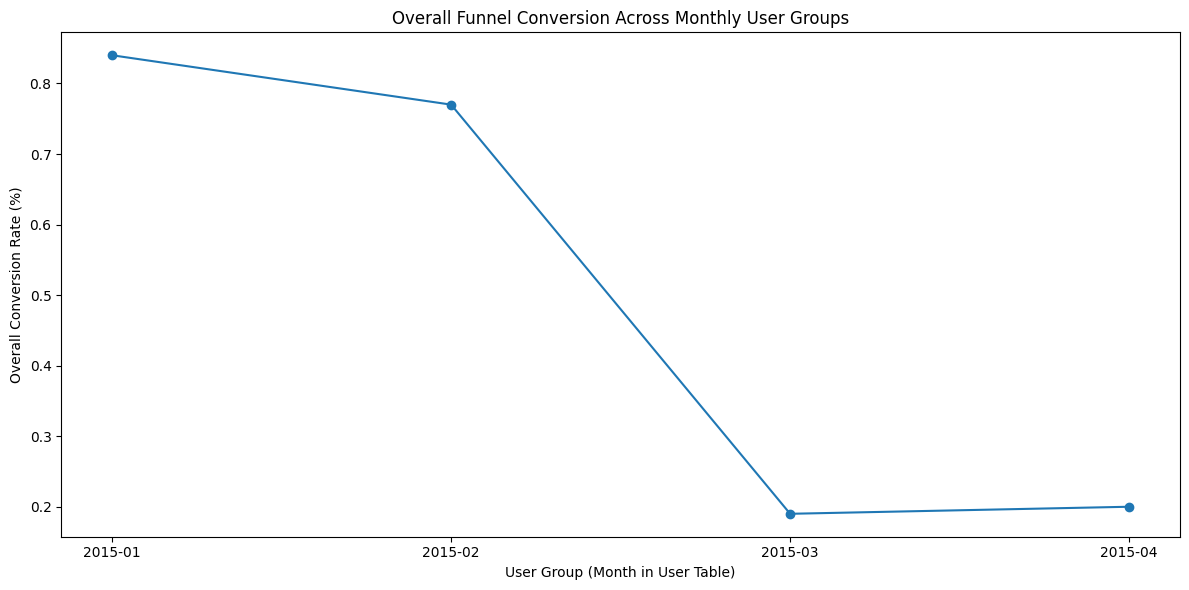

In [31]:
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_funnel['month'],
    monthly_funnel['Overall Conversion (%)'],
    marker='o'
)

plt.title('Overall Funnel Conversion Across Monthly User Groups')
plt.xlabel('User Group (Month in User Table)')
plt.ylabel('Overall Conversion Rate (%)')
plt.tight_layout()
plt.show()

### 9. How did funnel progression differ across Monthly user groups?

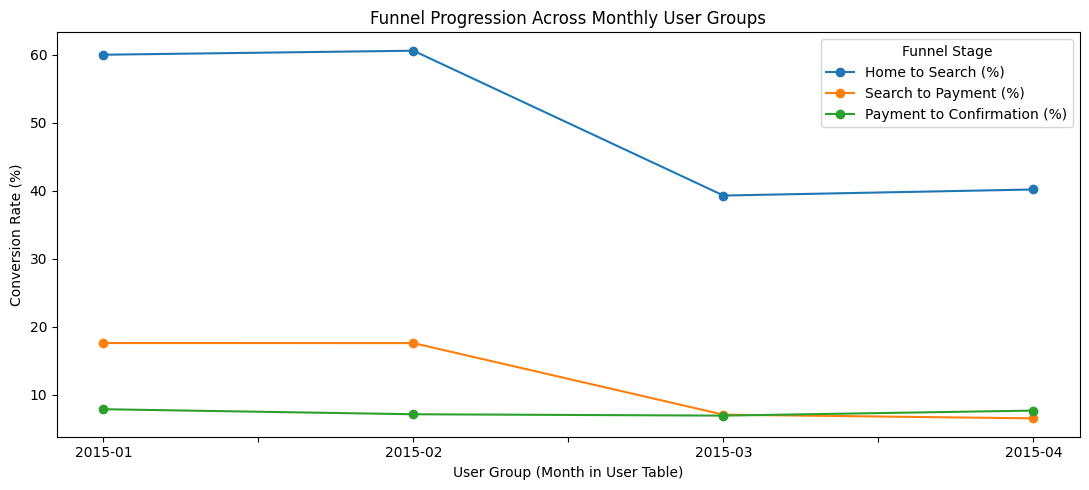

In [32]:
stage_columns = [
    'Home to Search (%)',
    'Search to Payment (%)',
    'Payment to Confirmation (%)'
]

monthly_funnel.plot(
    x='month',
    y=stage_columns,
    marker='o',
    figsize=(11, 5)
)

plt.title('Funnel Progression Across Monthly User Groups')
plt.xlabel('User Group (Month in User Table)')
plt.ylabel('Conversion Rate (%)')
plt.xticks(rotation=0)
plt.legend(title='Funnel Stage')
plt.tight_layout()
plt.show()

The January and February user cohorts recorded overall conversion rates of 0.84% and 0.77%, respectively. Conversion declined sharply for the March cohort to 0.19% and remained similarly low for the April cohort at 0.20%, indicating substantially weaker funnel performance among users associated with the later cohorts.

Compared with the February cohort, the March cohort experienced a 21.27 percentage-point decline in Home → Search conversion and a 10.51 percentage-point decline in Search → Payment conversion. In contrast, Payment → Confirmation remained relatively stable, differing by only 0.20 percentage points.

The factors affecting user progression after February should therefore be investigated within the early and middle stages of the funnel. The April cohort performed similarly to the March cohort, suggesting that the weaker conversion pattern persisted across both cohorts.

## Cross Analysis

### 10. How does conversion performance differ between desktop and mobile users across the funnel? (Device x Funnel Analysis)

In [33]:
# Home stage
home_device = ht.merge(ut[['user_id', 'device']],on='user_id')

home_counts = home_device.groupby('device')['user_id'].nunique().reset_index(name='Home Users')

# Search stage
search_device = st.merge(ut[['user_id', 'device']],on='user_id')

search_counts = search_device.groupby('device')['user_id'].nunique().reset_index(name='Search Users')

# Payment stage
payment_device = pt.merge(ut[['user_id', 'device']],on='user_id')

payment_counts = payment_device.groupby('device')['user_id'].nunique().reset_index(name='Payment Users')

# Confirmation stage
confirmation_device = pct.merge(ut[['user_id', 'device']], on='user_id')

confirmation_counts = confirmation_device.groupby('device')['user_id'].nunique().reset_index(name='Confirmed Users')

In [34]:
device_funnel = home_counts.merge(search_counts, on='device').merge(payment_counts, on='device').merge(confirmation_counts, on='device')

In [35]:
device_funnel['Home to Search (%)'] = (device_funnel['Search Users'] / device_funnel['Home Users'] * 100).round(2)

device_funnel['Search to Payment (%)'] = (device_funnel['Payment Users'] / device_funnel['Search Users'] * 100).round(2)

device_funnel['Payment to Confirmation (%)'] = (device_funnel['Confirmed Users'] / device_funnel['Payment Users'] * 100).round(2)

In [36]:
device_funnel[
    ['device', 
     'Home Users', 
     'Search Users', 
     'Payment Users', 
     'Confirmed Users', 
     'Home to Search (%)', 
     'Search to Payment (%)', 
     'Payment to Confirmation (%)']
]

,device,Home Users,Search Users,Payment Users,Confirmed Users,Home to Search (%),Search to Payment (%),Payment to Confirmation (%)
0,Desktop,60200,30100,3010,150,50.0,10.0,4.98
1,Mobile,30200,15100,3020,302,50.0,20.0,10.00


In [37]:
plot_data = device_funnel.melt(
    id_vars='device',
    value_vars=[
        'Home to Search (%)',
        'Search to Payment (%)',
        'Payment to Confirmation (%)'
    ],
    var_name='Funnel Stage',
    value_name='Conversion Rate (%)'
)

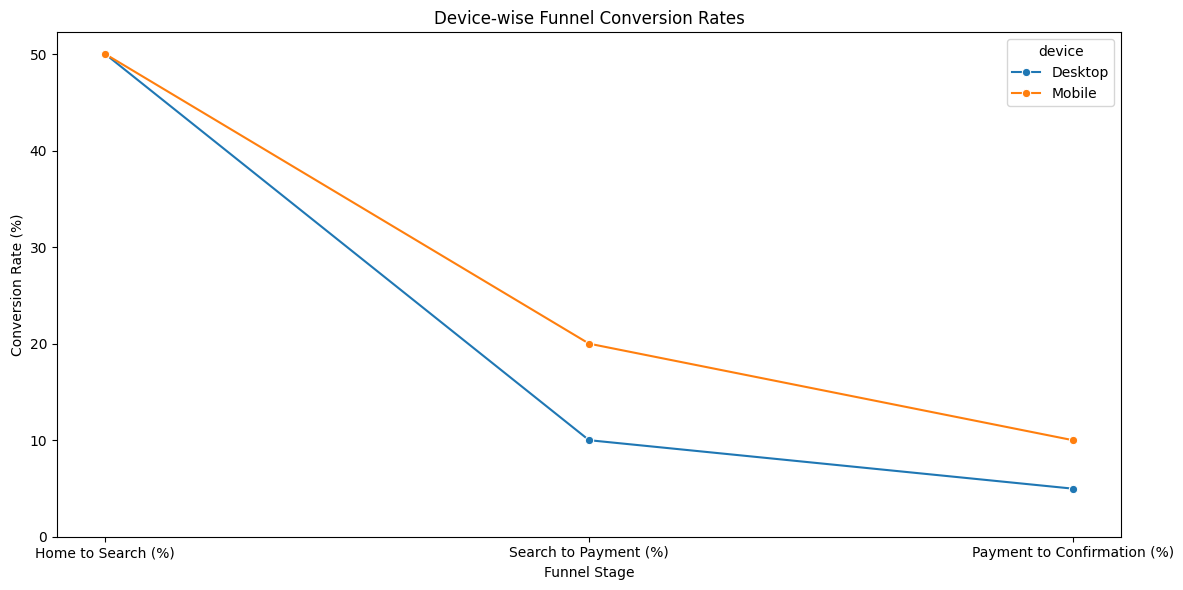

In [38]:
plt.figure(figsize=(12,6))

sns.lineplot(
    data=plot_data,
    x='Funnel Stage',
    y='Conversion Rate (%)',
    hue='device',
    marker='o'
)

plt.title('Device-wise Funnel Conversion Rates')
plt.xlabel('Funnel Stage')
plt.ylabel('Conversion Rate (%)')

plt.ylim(bottom=0)

plt.tight_layout()
plt.show()

Desktop and mobile users progress through the Home to Search stage at an identical rate (50%), indicating that both devices generate similar levels of initial engagement. However, conversion performance diverges significantly in the later stages of the funnel.

Desktop users convert at only 10% from Search to Payment, compared with 20% for mobile users, and their Payment to Confirmation conversion rate is also approximately half that of mobile users (4.98% vs. 10.00%). This indicates that the lower overall desktop conversion rate is driven primarily by poor progression during the purchase journey rather than weaker initial user engagement.

The factors affecting the desktop purchase experience, particularly during the Search to Payment and Payment to Confirmation stages, should therefore be prioritised for investigation, as these stages present the greatest opportunity to improve overall conversions.

## Business Recommendations

In [39]:
recommendations = pd.DataFrame({
    'Priority': [1, 2, 3, 4, 5],

    'Key Finding': [
        'Payment → Confirmation is the weakest funnel transition, with the highest abandonment rate',
        'Desktop users struggle more than mobile users during the purchase journey',
        'Users associated with the March and April groups exhibited substantially weaker funnel performance',
        'Search → Payment accounts for the largest absolute customer loss in the funnel',
        'Gender does not appear to be a major driver of funnel performance'
    ],

    'Recommended Action': [
        'Investigate why users fail to complete their purchase by reviewing payment logs, technical errors, session recordings, and customer feedback before implementing improvements',
        'Evaluate the desktop purchase journey to identify usability or technical issues that may be preventing users from progressing beyond the Search stage',
        'Review any campaign, website, product, or operational changes introduced around March to understand the cause of the decline in conversions',
        'Analyse the Search → Payment journey to identify barriers that discourage users from moving forward and test improvements to reduce abandonment',
        'Prioritise optimisation efforts on funnel-stage and device-related issues rather than developing gender-specific strategies'
    ],

    'Why?': [
        'Only 7.5% of payment users complete their purchase, while 92.5% exit at this stage',
        'Desktop users convert at 10.00% and 4.98% in the final two stages, compared with 20.00% and 10.00% for mobile users',
        'Overall conversion fell from 0.77% in February to 0.19% in March',
        'Only 13.34% of users who reach the Search stage continue to the Payment stage',
        'Conversion differences between male and female users are relatively small compared with the device and funnel-stage gaps'
    ]
})

recommendations.style.hide(axis='index')

Priority,Key Finding,Recommended Action,Why?
1,"Payment → Confirmation is the weakest funnel transition, with the highest abandonment rate","Investigate why users fail to complete their purchase by reviewing payment logs, technical errors, session recordings, and customer feedback before implementing improvements","Only 7.5% of payment users complete their purchase, while 92.5% exit at this stage"
2,Desktop users struggle more than mobile users during the purchase journey,Evaluate the desktop purchase journey to identify usability or technical issues that may be preventing users from progressing beyond the Search stage,"Desktop users convert at 10.00% and 4.98% in the final two stages, compared with 20.00% and 10.00% for mobile users"
3,Users associated with the March and April groups exhibited substantially weaker funnel performance,"Review any campaign, website, product, or operational changes introduced around March to understand the cause of the decline in conversions",Overall conversion fell from 0.77% in February to 0.19% in March
4,Search → Payment accounts for the largest absolute customer loss in the funnel,Analyse the Search → Payment journey to identify barriers that discourage users from moving forward and test improvements to reduce abandonment,Only 13.34% of users who reach the Search stage continue to the Payment stage
5,Gender does not appear to be a major driver of funnel performance,Prioritise optimisation efforts on funnel-stage and device-related issues rather than developing gender-specific strategies,Conversion differences between male and female users are relatively small compared with the device and funnel-stage gaps


## Final Summary

The analysis found that the overall funnel conversion rate was only 0.50%, indicating significant customer loss throughout the purchase journey. While the Search → Payment stage accounted for the largest absolute drop-off in users, the Payment → Confirmation stage recorded the highest abandonment rate, with only 7.50% of users completing their purchase after reaching the payment stage. These findings highlight the final stages of the funnel as key areas requiring further investigation. Additionally, desktop users converted at substantially lower rates than mobile users during the later stages of the journey, making the desktop purchase experience another important priority for optimisation.

Users associated with the March and April groups also exhibited considerably weaker funnel performance than those in January and February, although the available data does not identify the underlying cause. In contrast, gender differences in conversion were minimal and are therefore unlikely to represent a meaningful optimisation opportunity. Overall, the analysis identifies the primary bottlenecks within the funnel and provides a clear direction for prioritising future investigation and conversion improvement efforts.

Overall, the analysis successfully identifies the key bottlenecks limiting funnel performance and highlights the areas with the greatest potential for improving conversions. While additional data would be required to determine the exact causes of user abandonment, the findings provide a clear, evidence-based foundation for prioritising future investigation and optimisation efforts.

## Limitaions in the dataset

This analysis identifies where users leave the funnel but does not determine the underlying causes of abandonment. The dataset does not include behavioural metrics, pricing information, website performance data, or customer feedback. Additionally, the funnel-stage tables do not contain event timestamps, so the cohort analysis compares users based on the date recorded in the user table rather than the exact timing of each funnel-stage event. Further investigation using website analytics, session recordings, payment logs, and controlled experiments would be required to validate the recommendations.